# Electricity Demand Forecasting

## 1. Data Exploration

### Objective
To analyse historical electricity demand data and understand its structure, quality, and demand patterns before applying Machine Learning algorithms.

### Dataset
AEP Hourly Electricity Demand Dataset

In [4]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display all columns
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Load the electricity demand dataset

df = pd.read_csv("AEP_hourly.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
# Display the first 5 records

df.head()

,Datetime,AEP_MW
0,2004-12-31 01:00:00,13478.0
1,2004-12-31 02:00:00,12865.0
2,2004-12-31 03:00:00,12577.0
3,2004-12-31 04:00:00,12517.0
4,2004-12-31 05:00:00,12670.0


In [7]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check statistical summary
print("\nStatistical Summary:")
df.describe()

Dataset Shape: (121273, 2)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 121273 entries, 0 to 121272
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  121273 non-null  str    
 1   AEP_MW    121273 non-null  float64
dtypes: float64(1), str(1)
memory usage: 4.0 MB

Missing Values:
Datetime    0
AEP_MW      0
dtype: int64

Statistical Summary:


,AEP_MW
count,121273.000000
mean,15499.513717
std,2591.399065
min,9581.000000
25%,13630.000000
50%,15310.000000
75%,17200.000000
max,25695.000000


In [8]:
# Convert Datetime column into datetime format
df["Datetime"] = pd.to_datetime(df["Datetime"])

# Sort records by date and time
df = df.sort_values("Datetime").reset_index(drop=True)

# Display dataset time period
print("Starting Date:", df["Datetime"].min())
print("Ending Date:", df["Datetime"].max())

# Check duplicate timestamps
print("\nDuplicate Records:", df["Datetime"].duplicated().sum())

# Check time intervals between records
print("\nTime Interval:")
print(df["Datetime"].diff().value_counts().head())

Starting Date: 2004-10-01 01:00:00
Ending Date: 2018-08-03 00:00:00

Duplicate Records: 4

Time Interval:
Datetime
0 days 01:00:00    121241
0 days 02:00:00        27
0 days 00:00:00         4
Name: count, dtype: int64


In [9]:
# Display duplicate timestamp records
duplicates = df[df["Datetime"].duplicated(keep=False)]

print("Duplicate timestamp records:")
display(duplicates)

# Find intervals greater than one hour
time_diff = df["Datetime"].diff()

gaps = df.loc[time_diff > pd.Timedelta(hours=1), ["Datetime"]].copy()

gaps["Time Difference"] = time_diff[time_diff > pd.Timedelta(hours=1)]

print("\nGaps greater than one hour:")
display(gaps)

# Count duplicate timestamps
print("\nTotal duplicate timestamps:", df["Datetime"].duplicated().sum())

# Count larger time gaps
print("Total gaps:", len(gaps))

Duplicate timestamp records:


,Datetime,AEP_MW
88394,2014-11-02 02:00:00,12994.0
88395,2014-11-02 02:00:00,13190.0
97130,2015-11-01 02:00:00,10785.0
97131,2015-11-01 02:00:00,10542.0
106034,2016-11-06 02:00:00,10964.0
106035,2016-11-06 02:00:00,11008.0
114770,2017-11-05 02:00:00,10596.0
114771,2017-11-05 02:00:00,10446.0



Gaps greater than one hour:


,Datetime,Time Difference
721,2004-10-31 03:00:00,0 days 02:00:00
4417,2005-04-03 04:00:00,0 days 02:00:00
9455,2005-10-30 03:00:00,0 days 02:00:00
13151,2006-04-02 04:00:00,0 days 02:00:00
18189,2006-10-29 03:00:00,0 days 02:00:00
21381,2007-03-11 04:00:00,0 days 02:00:00
27091,2007-11-04 03:00:00,0 days 02:00:00
30115,2008-03-09 04:00:00,0 days 02:00:00
35825,2008-11-02 03:00:00,0 days 02:00:00
38849,2009-03-08 04:00:00,0 days 02:00:00



Total duplicate timestamps: 4
Total gaps: 27


In [10]:
# Investigate the three unusual gaps

unusual_dates = [
    "2010-12-10 01:00:00",
    "2012-12-06 05:00:00",
    "2014-03-11 15:00:00"
]

for date in unusual_dates:

    target = pd.Timestamp(date)

    print("\nRecords around:", target)

    index = df.index[df["Datetime"] == target][0]

    display(df.iloc[max(0, index-3):index+3])


Records around: 2010-12-10 01:00:00


,Datetime,AEP_MW
54247,2010-12-09 21:00:00,20600.0
54248,2010-12-09 22:00:00,20130.0
54249,2010-12-09 23:00:00,19078.0
54250,2010-12-10 01:00:00,17373.0
54251,2010-12-10 02:00:00,17030.0
54252,2010-12-10 03:00:00,16794.0



Records around: 2012-12-06 05:00:00


,Datetime,AEP_MW
71694,2012-12-06 01:00:00,14946.0
71695,2012-12-06 02:00:00,14707.0
71696,2012-12-06 03:00:00,14711.0
71697,2012-12-06 05:00:00,15192.0
71698,2012-12-06 06:00:00,16096.0
71699,2012-12-06 07:00:00,17657.0



Records around: 2014-03-11 15:00:00


,Datetime,AEP_MW
82740,2014-03-11 11:00:00,15548.0
82741,2014-03-11 12:00:00,15032.0
82742,2014-03-11 13:00:00,14839.0
82743,2014-03-11 15:00:00,14405.0
82744,2014-03-11 16:00:00,14132.0
82745,2014-03-11 17:00:00,14125.0


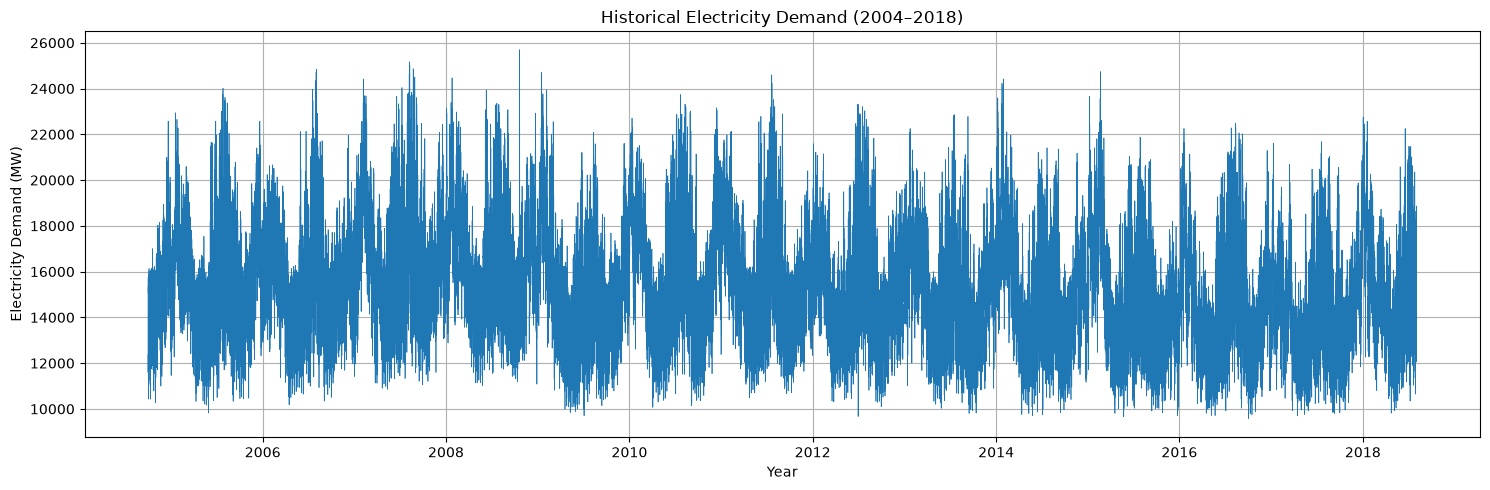

In [11]:
import matplotlib.pyplot as plt

# Plot historical electricity demand
plt.figure(figsize=(15, 5))

plt.plot(df["Datetime"], df["AEP_MW"], linewidth=0.5)

plt.title("Historical Electricity Demand (2004–2018)")
plt.xlabel("Year")
plt.ylabel("Electricity Demand (MW)")

plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
# Convert Datetime column into datetime format
df["Datetime"] = pd.to_datetime(df["Datetime"])

# Extract hour from datetime
df["Hour"] = df["Datetime"].dt.hour

# Calculate average electricity demand for each hour
hourly_demand = df.groupby("Hour")["AEP_MW"].mean()

# Display the result
print("Average Electricity Demand by Hour:")
display(hourly_demand)

Average Electricity Demand by Hour:


Hour
0     14651.191569
1     13891.478433
2     13432.062995
3     13184.049008
4     13095.193350
5     13240.535813
6     13802.401464
7     14781.668381
8     15478.830233
9     15822.653740
10    16084.283934
11    16306.315592
12    16398.177087
13    16477.793035
14    16534.660202
15    16492.810645
16    16444.506134
17    16542.038781
18    16762.940047
19    16868.728334
20    16821.335180
21    16763.806292
22    16468.967550
23    15632.594183
Name: AEP_MW, dtype: float64

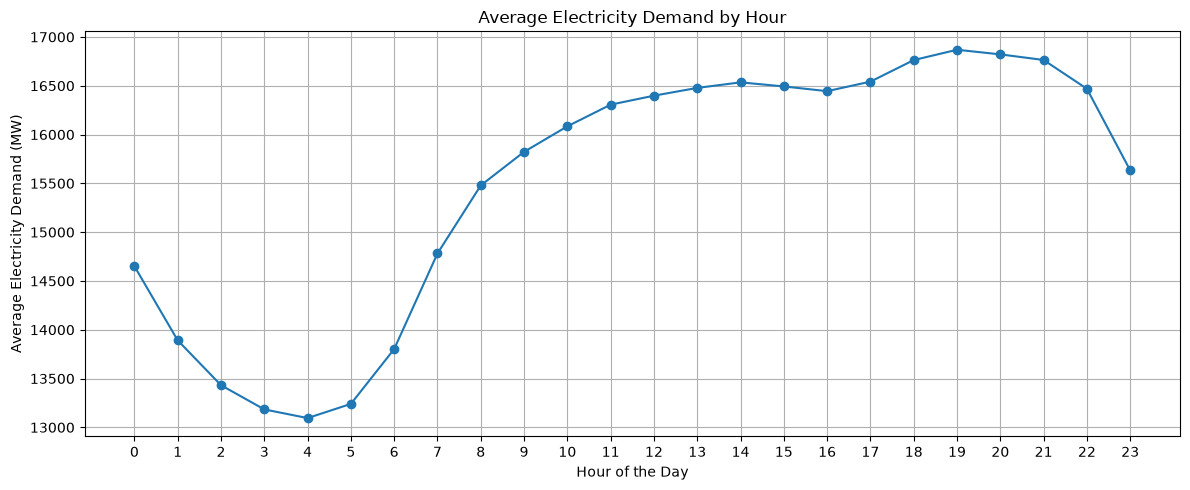

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(hourly_demand.index, hourly_demand.values, marker="o")

plt.title("Average Electricity Demand by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Electricity Demand (MW)")

plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
# Extract day of the week
df["Day"] = df["Datetime"].dt.day_name()

# Calculate average demand for each day
daily_demand = df.groupby("Day")["AEP_MW"].mean()

# Arrange days in correct order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_demand = daily_demand.reindex(day_order)

# Display results
print("Average Electricity Demand by Day:")
display(daily_demand)

Average Electricity Demand by Day:


Day
Monday       15810.973684
Tuesday      16057.615571
Wednesday    16013.589739
Thursday     16028.138281
Friday       15773.123911
Saturday     14610.979628
Sunday       14200.754680
Name: AEP_MW, dtype: float64

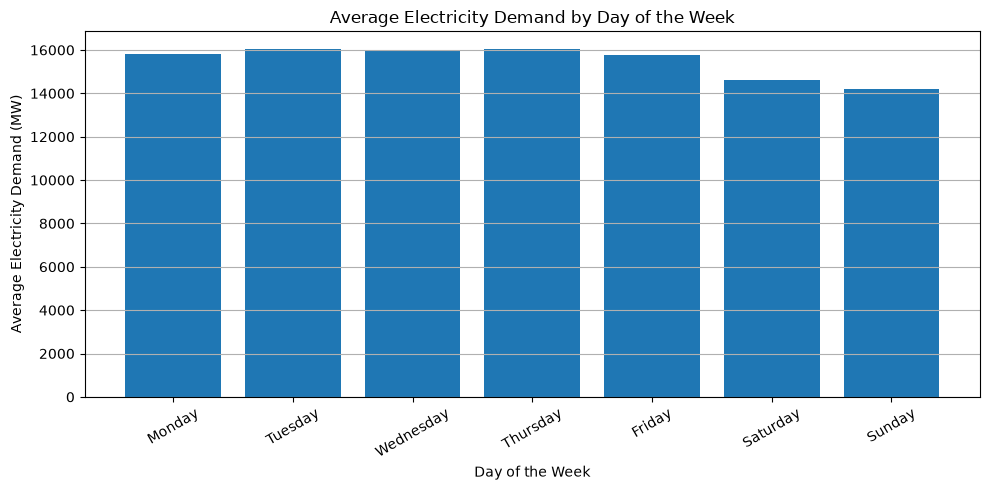

In [15]:
plt.figure(figsize=(10, 5))

plt.bar(daily_demand.index, daily_demand.values)

plt.title("Average Electricity Demand by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Electricity Demand (MW)")

plt.xticks(rotation=30)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [16]:
# Extract month from datetime
df["Month"] = df["Datetime"].dt.month

# Calculate average demand for each month
monthly_demand = df.groupby("Month")["AEP_MW"].mean()

# Display results
print("Average Electricity Demand by Month:")
display(monthly_demand)


Average Electricity Demand by Month:


Month
1     17431.269009
2     17022.815084
3     15376.835720
4     13823.857511
5     14006.393817
6     15630.021825
7     16349.853303
8     16424.881699
9     14657.280556
10    13938.926431
11    14930.405676
12    16445.609084
Name: AEP_MW, dtype: float64

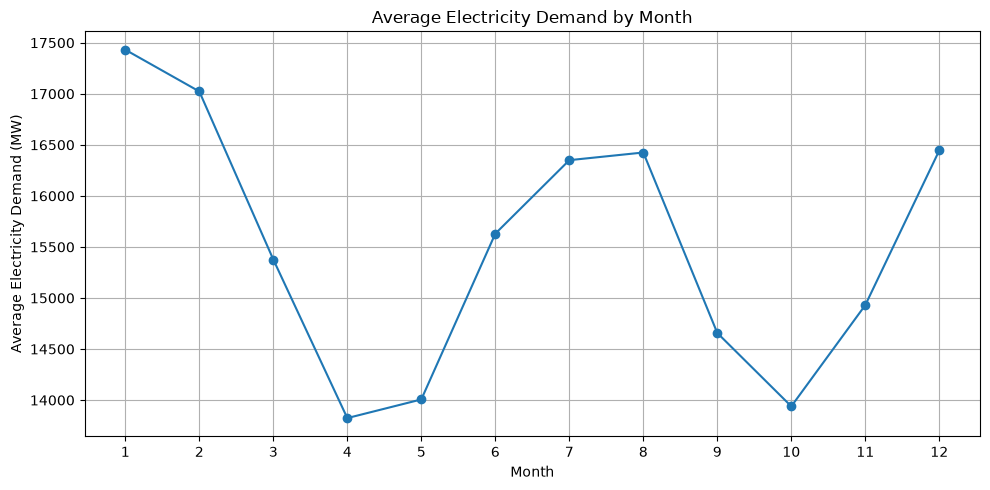

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_demand.index, monthly_demand.values, marker="o")

plt.title("Average Electricity Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Electricity Demand (MW)")

plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

Year
2004    15176.724388
2005    15842.990865
2006    15737.224252
2007    16645.519297
2008    16536.655659
2009    15254.111669
2010    16008.619504
2011    15815.389472
2012    15352.940667
2013    15198.211578
2014    15169.078890
2015    14868.922603
2016    14784.225979
2017    14483.738356
2018    15290.612734
Name: AEP_MW, dtype: float64


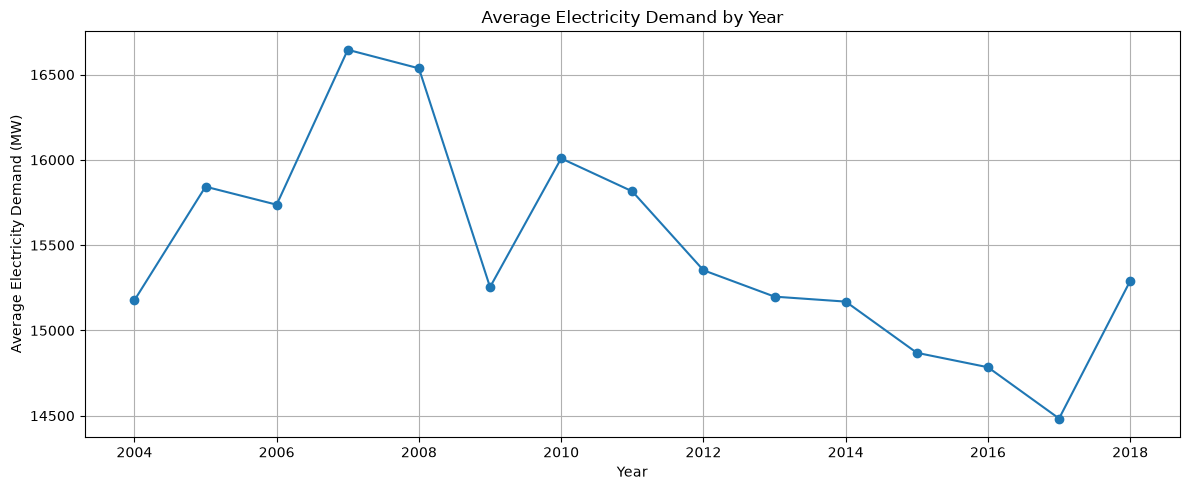

In [18]:
# Convert Datetime column into datetime format
df["Datetime"] = pd.to_datetime(df["Datetime"])

# Extract year
df["Year"] = df["Datetime"].dt.year

# Calculate average demand for each year
yearly_demand = df.groupby("Year")["AEP_MW"].mean()

# Display yearly average demand
print(yearly_demand)

# Plot yearly electricity demand
plt.figure(figsize=(12, 5))

plt.plot(yearly_demand.index, yearly_demand.values, marker="o")

plt.title("Average Electricity Demand by Year")
plt.xlabel("Year")
plt.ylabel("Average Electricity Demand (MW)")

plt.grid(True)
plt.tight_layout()
plt.show()

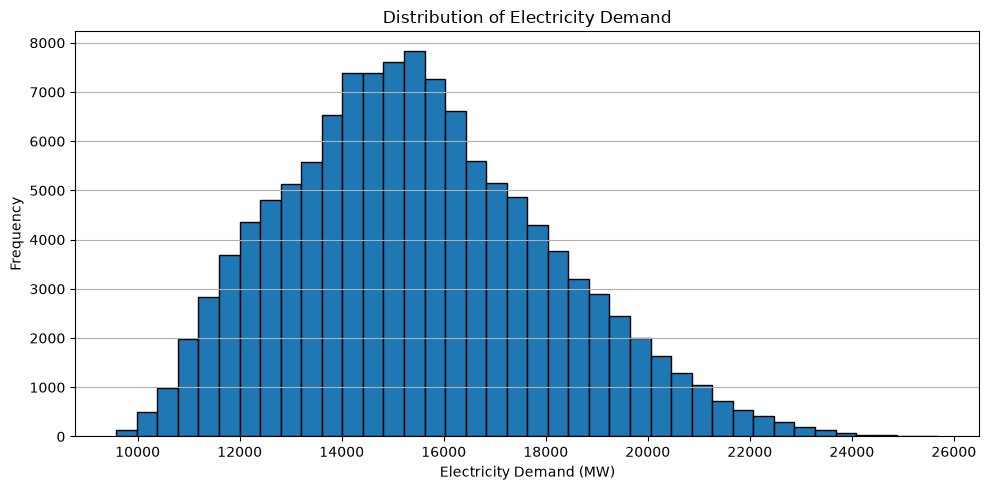

In [19]:
# Plot distribution of electricity demand

plt.figure(figsize=(10, 5))

plt.hist(df["AEP_MW"], bins=40, edgecolor="black")

plt.title("Distribution of Electricity Demand")
plt.xlabel("Electricity Demand (MW)")
plt.ylabel("Frequency")

plt.grid(axis="y")
plt.tight_layout()
plt.show()

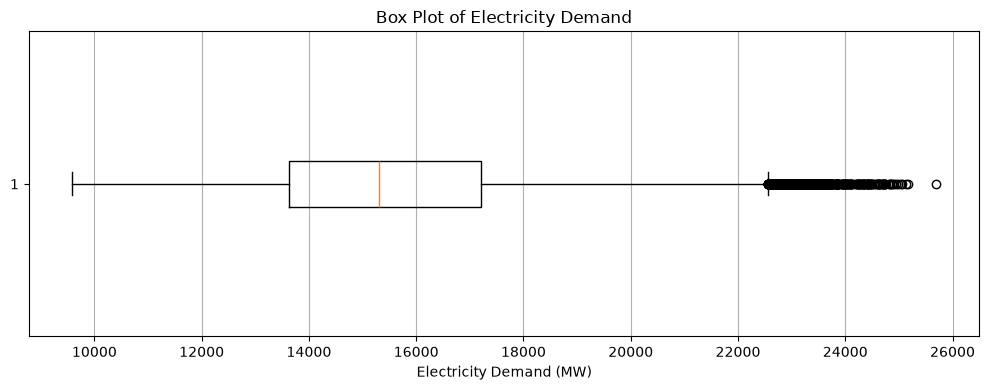

In [21]:
# Detect outliers using a box plot

plt.figure(figsize=(10, 4))

plt.boxplot(df["AEP_MW"], orientation="horizontal")

plt.title("Box Plot of Electricity Demand")
plt.xlabel("Electricity Demand (MW)")

plt.grid(axis="x")
plt.tight_layout()
plt.show()

In [22]:
# Calculate first and third quartiles
Q1 = df["AEP_MW"].quantile(0.25)
Q3 = df["AEP_MW"].quantile(0.75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[
    (df["AEP_MW"] < lower_limit) |
    (df["AEP_MW"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("\nTotal Outliers:", len(outliers))
print("Percentage of Outliers:", round(len(outliers) / len(df) * 100, 2), "%")

# Display first 10 outliers
outliers.head(10)

Q1: 13630.0
Q3: 17200.0
IQR: 3570.0
Lower Limit: 8275.0
Upper Limit: 22555.0

Total Outliers: 667
Percentage of Outliers: 0.55 %


,Datetime,AEP_MW,Hour,Day,Month,Year
1927,2004-12-20 09:00:00,22577.0,9,Monday,12,2004
2622,2005-01-18 08:00:00,22940.0,8,Tuesday,1,2005
2623,2005-01-18 09:00:00,22886.0,9,Tuesday,1,2005
2766,2005-01-24 08:00:00,22652.0,8,Monday,1,2005
2767,2005-01-24 09:00:00,22639.0,9,Monday,1,2005
6469,2005-06-27 16:00:00,22579.0,16,Monday,6,2005
6470,2005-06-27 17:00:00,22558.0,17,Monday,6,2005
7044,2005-07-21 15:00:00,22791.0,15,Thursday,7,2005
7045,2005-07-21 16:00:00,23013.0,16,Thursday,7,2005
7046,2005-07-21 17:00:00,22970.0,17,Thursday,7,2005


In [24]:
df["Day_Type"] = np.where(
    df["Datetime"].dt.day_of_week < 5,
    "Weekday",
    "Weekend"
)

day_type_demand = df.groupby("Day_Type")["AEP_MW"].mean()

print("Average Electricity Demand: Weekday vs Weekend")
display(day_type_demand)

Average Electricity Demand: Weekday vs Weekend


Day_Type
Weekday    15936.687674
Weekend    14405.985593
Name: AEP_MW, dtype: float64

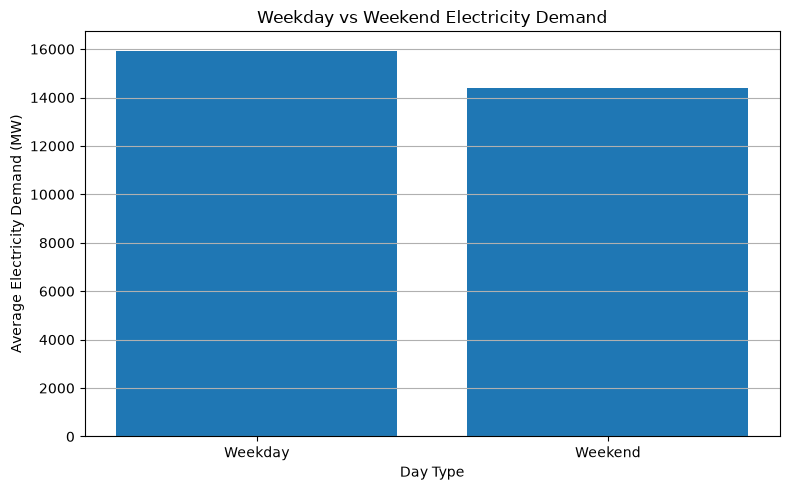

In [25]:
# Visualize weekday vs weekend demand

plt.figure(figsize=(8, 5))

plt.bar(
    day_type_demand.index,
    day_type_demand.values
)

plt.title("Weekday vs Weekend Electricity Demand")
plt.xlabel("Day Type")
plt.ylabel("Average Electricity Demand (MW)")

plt.grid(axis="y")
plt.tight_layout()
plt.show()

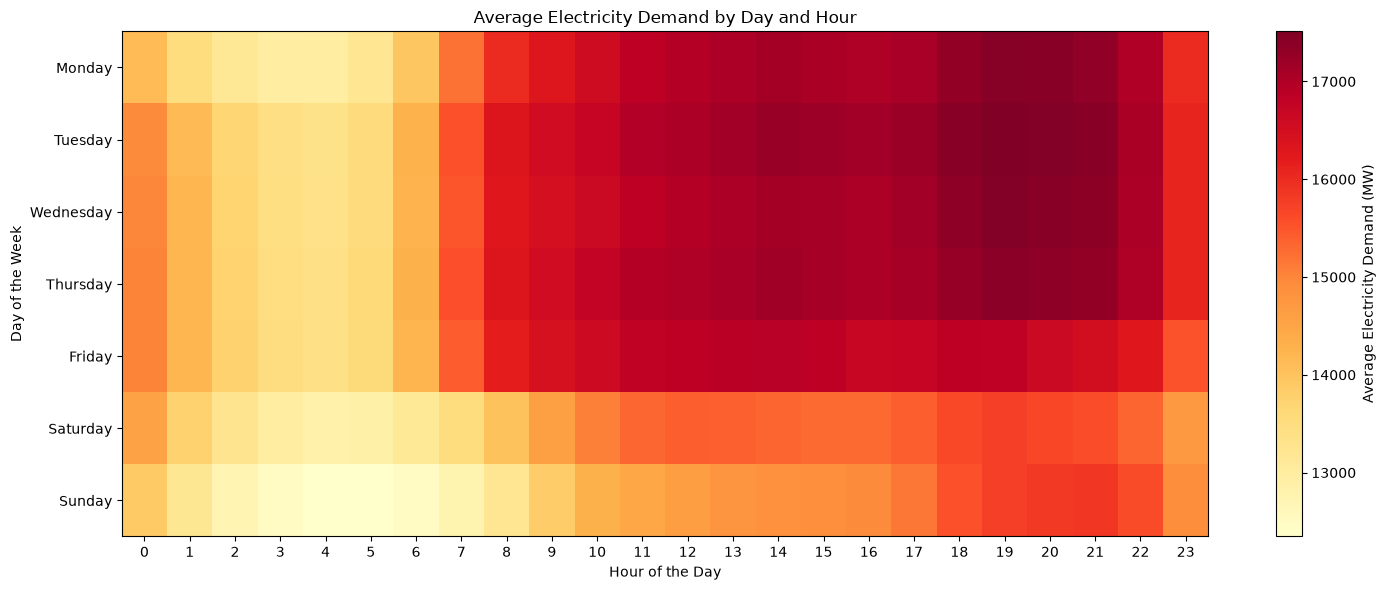

In [26]:
# Calculate average demand for each hour and day
heatmap_data = df.pivot_table(
    values="AEP_MW",
    index="Day",
    columns="Hour",
    aggfunc="mean"
)

# Arrange days in correct order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

heatmap_data = heatmap_data.reindex(day_order)

# Plot heatmap
plt.figure(figsize=(15, 6))

plt.imshow(heatmap_data, aspect="auto", cmap="YlOrRd")

plt.colorbar(label="Average Electricity Demand (MW)")
plt.xticks(range(24), range(24))
plt.yticks(range(7), day_order)

plt.xlabel("Hour of the Day")
plt.ylabel("Day of the Week")
plt.title("Average Electricity Demand by Day and Hour")

plt.tight_layout()
plt.show()

In [27]:
hourly_variation = df.groupby("Hour")["AEP_MW"].std()

print("Hourly Electricity Demand Variation:")
display(hourly_variation)

Hourly Electricity Demand Variation:


Hour
0     1922.171307
1     1897.726238
2     1921.590970
3     1958.604723
4     2007.667203
5     2079.752585
6     2207.759620
7     2479.536772
8     2571.766058
9     2348.520702
10    2148.937347
11    2076.914400
12    2094.985123
13    2190.369401
14    2328.461384
15    2435.828830
16    2503.420154
17    2529.514911
18    2512.706791
19    2482.097379
20    2316.962072
21    2141.079829
22    2093.875337
23    2005.337497
Name: AEP_MW, dtype: float64

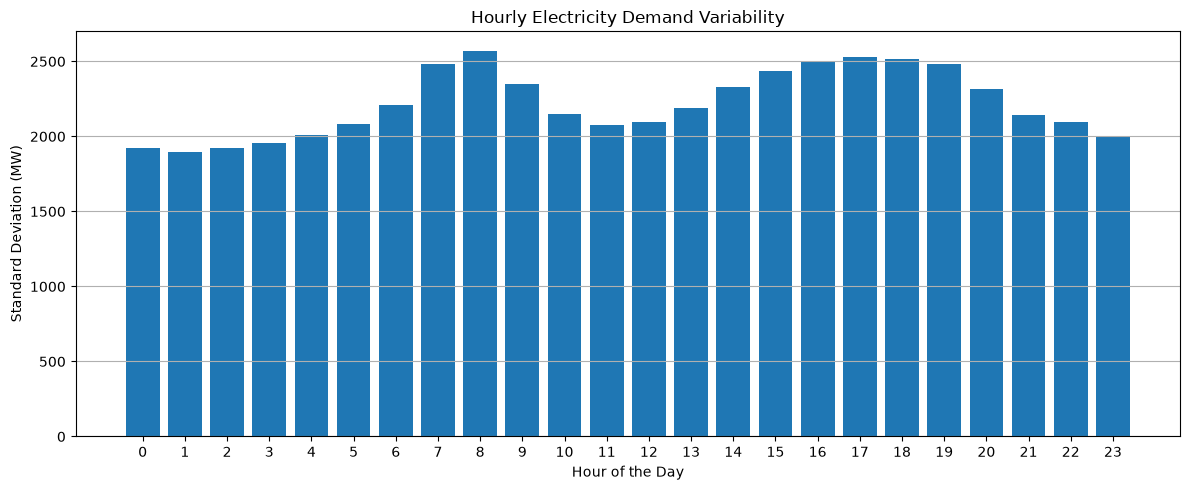

In [28]:
plt.figure(figsize=(12, 5))

plt.bar(hourly_variation.index, hourly_variation.values)

plt.title("Hourly Electricity Demand Variability")
plt.xlabel("Hour of the Day")
plt.ylabel("Standard Deviation (MW)")
plt.xticks(range(24))
plt.grid(axis="y")

plt.tight_layout()
plt.show()